# Task 3: Player Monthly Spending Prediction (Official Submission)
## CPE342 Machine Learning — Team ML009

### Executive Overview
- **Objective:** Predict player monthly spending (`spending_30d` in THB) for Karena Thailand.
- **Core Challenge:** The target variable exhibits severe **Zero-Inflation** (~48.1% non-spenders with `spending_30d = 0`) paired with a **heavy-tailed right-skewed distribution** among active spenders.
- **Evaluation Metric:** Normalized Mean Absolute Error (NMAE), where higher scores indicate superior predictive accuracy (maximum = 1.0):
  $$\text{NMAE} = \frac{1}{1 + \frac{\sum_{i=1}^{N} |y_i - \hat{y}_i|}{\sum_{i=1}^{N} y_i}}$$
- **Methodological Architecture:**
  1. **Two-Stage Hurdle Framework:** Decouples spending propensity $P(Y > 0 \mid X)$ from conditional spending magnitude $E[Y \mid Y > 0, X]$.
  2. **The Holy Trinity Ensemble:** Combines three structurally diverse GBDT architectures (**LightGBM**, **XGBoost**, and **CatBoost**) via 3-way convex simplex blending.
  3. **Optuna-Tuned Tweedie Regression:** Models conditional spending directly on the monetary scale using Compound Poisson-Gamma deviance ($1 < p < 2$).
  4. **Robust Generalization:** Employs **Conservative Global Thresholding** ($\tau \in [0.45, 0.50]$, without post-hoc scalar calibration) and **Multi-Objective Submission Blending** between the Baseline Log-MAE Model and the Tweedie-Optimized Ensemble.

## 1. Environment Setup & Data Ingestion

We initialize reproducible random seeds, import core gradient boosting frameworks (`lightgbm`, `xgboost`, `catboost`), and automatically resolve the dataset path across standard workspace layouts.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, log_loss, mean_absolute_error

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, CatBoostRegressor
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Global configuration
SEED = 42
N_SPLITS = 5
OPTUNA_TRIALS = 15
EPSILON = 1e-6
np.random.seed(SEED)

# Resolve data directory
CANDIDATE_DIRS = [
    "../data/task3",
    "data/task3",
    "../../CPE342-Hackathon/03_regression",
    "../CPE342-Hackathon/03_regression",
    "."
]
DATA_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(os.path.join(d, "train.csv"))), "../data/task3")

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

ID_COL = "player_id" if "player_id" in train_df.columns else train_df.columns[0]
TARGET_COL = "spending_30d" if "spending_30d" in train_df.columns else [c for c in train_df.columns if c not in test_df.columns][0]

print(f"Data Directory : {os.path.abspath(DATA_DIR)}")
print(f"Train Shape    : {train_df.shape} | Test Shape : {test_df.shape}")

Data Directory : d:\WORK\STUDY\Y3\CPE342 MACHINE LEARNING\Project-ML\cpe342-ML009\data\task3
Train Shape    : (104000, 34) | Test Shape : (25889, 33)


## 2. Exploratory Data Analysis: Zero-Inflation Diagnostics

We quantify the zero-inflation rate and active spender statistics on the training set. Nearly half of all players exhibit zero monthly expenditure, motivating a Two-Stage Hurdle decomposition.

In [2]:
n_total = len(train_df)
n_zero = (train_df[TARGET_COL] == 0).sum()
n_spenders = (train_df[TARGET_COL] > 0).sum()

print(f"Total Players     : {n_total:,}")
print(f"Non-Spenders (=0) : {n_zero:,} ({n_zero / n_total * 100:.2f}%)")
print(f"Active Spenders   : {n_spenders:,} ({n_spenders / n_total * 100:.2f}%)")
print("\nActive Spender Summary (THB):")
display(train_df.loc[train_df[TARGET_COL] > 0, TARGET_COL].describe().to_frame().T)

Total Players     : 104,000
Non-Spenders (=0) : 50,049 (48.12%)
Active Spenders   : 53,951 (51.88%)

Active Spender Summary (THB):


,count,mean,std,min,25%,50%,75%,max
spending_30d,53951.0,20234.883892,40053.792318,0.09,623.075,2314.05,14453.365,300000.0


## 3. Leak-Free Preprocessing & Median Imputation

To enforce strict **Zero Test Set Leakage**, `SimpleImputer(strategy='median')` is fitted exclusively on `X_train_raw` and applied to `X_test_raw` via `.transform()`. Median imputation is chosen over mean imputation to remain robust against extreme high-spending outliers.

In [3]:
feature_cols = [c for c in train_df.columns if c not in [ID_COL, TARGET_COL]]

X_train_raw = train_df[feature_cols].copy()
X_test_raw = test_df[feature_cols].copy()
y_train = train_df[TARGET_COL].copy()
y_train_binary = (y_train > 0).astype(int)

# Fit imputer exclusively on training features
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=feature_cols)
X_test_imp = pd.DataFrame(imputer.transform(X_test_raw), columns=feature_cols)

assert X_train_imp.isna().sum().sum() == 0, "Missing values remain in training set."
assert X_test_imp.isna().sum().sum() == 0, "Missing values remain in test set."
print(f"Median imputation verified. Base feature count: {len(feature_cols)}")

Median imputation verified. Base feature count: 32


## 4. Behavioral Feature Engineering

We construct **34 stateless, row-wise features** across four behavioral dimensions without computing cross-row statistics:
1. **Spending History & RFM (10 features):** Spending momentum, purchase velocity, recency, and log-compressed historical spend.
2. **Player Engagement (7 features):** Login recency, session intensity, loyalty score, and cross-game diversity.
3. **Social & VIP Status (7 features):** Guild interactions, limited-edition ownership, and competitive rank interactions.
4. **Segment Interactions (10 features):** Segment-specific historical spending slopes and discount sensitivity.

In [4]:
def create_spending_history_features(df: pd.DataFrame) -> pd.DataFrame:
    """Generate RFM, velocity, momentum, and log-spending features."""
    df = df.copy()
    hist = df["historical_spending"].fillna(0)
    prev = df["prev_month_spending"].fillna(0)
    n_tx = df["total_transactions"].fillna(0)
    atv = df["avg_transaction_value"].fillna(0)
    freq = df["purchase_frequency"].fillna(0)
    days_p = df["days_since_last_purchase"].fillna(0)
    age = df["account_age_days"].fillna(1)

    df["spending_momentum"] = prev / (hist + EPSILON)
    df["avg_spend_per_transaction"] = hist / (n_tx + EPSILON)
    df["purchase_intensity"] = freq * atv
    df["days_since_purchase_norm"] = days_p / (age + EPSILON)
    df["rfm_recency"] = -days_p
    df["rfm_frequency"] = freq
    df["rfm_monetary"] = hist
    df["log_historical_spending"] = np.log1p(hist.clip(lower=0))
    df["log_prev_month_spending"] = np.log1p(prev.clip(lower=0))
    df["log_avg_transaction_value"] = np.log1p(atv.clip(lower=0))
    return df


def create_engagement_features(df: pd.DataFrame) -> pd.DataFrame:
    """Generate player engagement, loyalty, and session intensity features."""
    df = df.copy()
    login_streak = df["daily_login_streak"].fillna(0)
    event_rate = df["event_participation_rate"].fillna(0)
    sessions_w = df["sessions_per_week"].fillna(0)
    avg_session = df["avg_session_length"].fillna(0)
    playtime = df["total_playtime_hours"].fillna(0)
    days_login = df["days_since_last_login"].fillna(999)
    age = df["account_age_days"].fillna(1)
    achiev_rate = df["achievement_completion_rate"].fillna(0)
    games_played = df["games_played"].fillna(0)
    cross_game = df["cross_game_activity"].fillna(0)

    df["engagement_score"] = 0.30 * login_streak + 0.40 * event_rate + 0.30 * sessions_w
    df["session_intensity"] = avg_session * sessions_w
    df["loyalty_score"] = age * (achiev_rate / 100.0)
    df["cross_game_ratio"] = cross_game / (games_played + EPSILON)
    df["daily_sessions"] = sessions_w / 7.0
    df["playtime_per_session"] = (playtime * 60) / (sessions_w * 30 + EPSILON)
    df["login_recency_flag"] = (days_login <= 3).astype(int)
    return df


def create_social_vip_features(df: pd.DataFrame) -> pd.DataFrame:
    """Generate social network, luxury, and VIP interaction features."""
    df = df.copy()
    friends = df["friend_count"].fillna(0)
    vip = df["vip_status"].fillna(0)
    premium = df["is_premium_member"].fillna(0)
    guild = df["guild_membership"].fillna(0)
    social = df["social_interactions"].fillna(0)
    limited_ed = df["owns_limited_edition"].fillna(0)
    comp_rank = df["competitive_rank"].fillna(0)
    tourney = df["tournament_participation"].fillna(0)
    engagement = df.get("engagement_score", pd.Series(0, index=df.index))

    df["social_vip_score"] = friends * vip
    df["premium_x_engagement"] = premium * engagement
    df["guild_social"] = guild * social
    df["luxury_index"] = limited_ed * vip
    df["competitive_vip"] = comp_rank * vip
    df["social_density"] = social / (friends + EPSILON)
    df["tournament_vip"] = tourney * vip
    return df


def create_interaction_features(df: pd.DataFrame) -> pd.DataFrame:
    """Generate segment-aware spending interactions and discount sensitivity."""
    df = df.copy()
    vip = df["vip_status"].fillna(0)
    premium = df["is_premium_member"].fillna(0)
    hist = df["historical_spending"].fillna(0)
    seg = df["segment"].fillna(-1)
    freq = df["purchase_frequency"].fillna(0)
    n_tx = df["total_transactions"].fillna(0)
    disc_pct = df["purchases_on_discount"].fillna(0)

    df["vip_x_history"] = vip * hist
    df["premium_x_history"] = premium * hist
    for seg_id in [0, 1, 2, 3]:
        df[f"seg{seg_id}_x_history"] = (seg == seg_id).astype(float) * hist
    df["is_whale_segment"] = (seg == 3).astype(int)
    df["is_spender_segment"] = seg.isin([2, 3]).astype(int)
    df["vip_purchase_rate"] = vip * freq
    df["discount_sensitivity"] = disc_pct / (n_tx + EPSILON)
    return df


def apply_feature_engineering(df: pd.DataFrame) -> pd.DataFrame:
    """Apply all four stateless feature engineering groups sequentially."""
    df = create_spending_history_features(df)
    df = create_engagement_features(df)
    df = create_social_vip_features(df)
    df = create_interaction_features(df)
    return df


X_train_eng = apply_feature_engineering(X_train_imp)
X_test_eng = apply_feature_engineering(X_test_imp)

print(f"Engineered Features Added : {X_train_eng.shape[1] - X_train_imp.shape[1]}")
print(f"Total Features            : {X_train_eng.shape[1]}")

Engineered Features Added : 34
Total Features            : 66


## 5. Automated Feature Selection

We execute a two-step feature selection pipeline strictly on the training set to minimize collinearity and noise:
1. **Multicollinearity Pruning:** Remove redundant features with pairwise Pearson correlation $|r| > 0.98$.
2. **Zero-Importance Screening:** Discard features receiving zero split importance in a baseline LightGBM classifier.

In [5]:
corr_matrix = X_train_eng.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
collinear_to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > 0.98)]

X_train_filtered = X_train_eng.drop(columns=collinear_to_drop)
X_test_filtered = X_test_eng.drop(columns=collinear_to_drop)

baseline_clf = lgb.LGBMClassifier(
    n_estimators=100, learning_rate=0.05, random_state=SEED, verbose=-1, n_jobs=-1
)
baseline_clf.fit(X_train_filtered, y_train_binary)
importances = pd.Series(baseline_clf.feature_importances_, index=X_train_filtered.columns)
zero_imp_cols = importances[importances == 0].index.tolist()

selected_features = [c for c in X_train_filtered.columns if c not in zero_imp_cols]
X_train_selected = X_train_filtered[selected_features].copy()
X_test_selected = X_test_filtered[selected_features].copy()

print(f"Collinear Dropped       : {len(collinear_to_drop)}")
print(f"Zero-Importance Dropped : {len(zero_imp_cols)}")
print(f"Final Selected Features : {len(selected_features)}")

Collinear Dropped       : 4
Zero-Importance Dropped : 6
Final Selected Features : 56


## 6. Evaluation Metric & Convex Simplex Optimization Utilities

We define the competition NMAE metric and an SLSQP-based solver that optimizes ensemble weights on the unit simplex ($w_i \ge 0, \sum w_i = 1$). Bounded convex blending guarantees variance reduction without introducing negative extrapolation or meta-learner overfitting.

In [6]:
def calculate_nmae(y_true, y_pred) -> float:
    """Compute Normalized Mean Absolute Error (higher is better, max = 1.0)."""
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.clip(np.asarray(y_pred, dtype=np.float64), 0, None)
    y_true_sum = np.sum(y_true)
    if y_true_sum == 0:
        return 0.0
    return float(1.0 / (1.0 + (np.sum(np.abs(y_true - y_pred)) / y_true_sum)))


def optimize_simplex_weights(oof_list, y_true, loss_fn) -> np.ndarray:
    """Find optimal non-negative weights summing to 1 via SLSQP."""
    n_models = len(oof_list)
    init_w = np.ones(n_models) / n_models
    bounds = [(0.0, 1.0)] * n_models
    constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}

    def objective(w):
        blend = sum(w[i] * oof_list[i] for i in range(n_models))
        return loss_fn(y_true, blend)

    res = minimize(objective, init_w, method="SLSQP", bounds=bounds, constraints=constraints)
    return res.x / np.sum(res.x)

## 7. Stage 1: Binary Classification ("The Holy Trinity")

Stage 1 estimates the spending probability $P(Y > 0 \mid X)$ across 5 Stratified K-Folds using three diverse GBDT architectures:
- **LightGBM:** Leaf-wise tree growth.
- **XGBoost:** Depth-wise histogram splitting.
- **CatBoost:** Symmetric (oblivious) trees resistant to continuous feature noise.

Out-Of-Fold (OOF) probabilities are combined via 3-way convex simplex optimization minimizing binary LogLoss.

In [7]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_s1_lgb, test_s1_lgb = np.zeros(len(train_df)), np.zeros(len(test_df))
oof_s1_xgb, test_s1_xgb = np.zeros(len(train_df)), np.zeros(len(test_df))
oof_s1_cat, test_s1_cat = np.zeros(len(train_df)), np.zeros(len(test_df))
stage1_lgb_models = []

lgb_cls_params = {
    "objective": "binary", "metric": "binary_logloss", "boosting_type": "gbdt",
    "learning_rate": 0.03, "num_leaves": 31, "max_depth": 6, "min_child_samples": 30,
    "subsample": 0.8, "colsample_bytree": 0.8, "reg_alpha": 0.1, "reg_lambda": 1.0,
    "n_estimators": 1000, "random_state": SEED, "n_jobs": -1, "verbose": -1
}

xgb_cls_params = {
    "objective": "binary:logistic", "eval_metric": "logloss", "learning_rate": 0.03,
    "max_depth": 6, "subsample": 0.8, "colsample_bytree": 0.8, "reg_alpha": 0.1,
    "reg_lambda": 1.0, "n_estimators": 1000, "random_state": SEED, "n_jobs": -1, "tree_method": "hist"
}

cat_cls_params = {
    "loss_function": "Logloss", "eval_metric": "Logloss", "learning_rate": 0.04,
    "depth": 6, "l2_leaf_reg": 3.0, "iterations": 1000, "random_seed": SEED, "verbose": 0
}

print("Training Stage 1 Classifiers (5-Fold Stratified CV)...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_selected, y_train_binary)):
    X_tr, y_tr = X_train_selected.iloc[train_idx], y_train_binary.iloc[train_idx]
    X_va, y_va = X_train_selected.iloc[val_idx], y_train_binary.iloc[val_idx]

    clf_lgb = lgb.LGBMClassifier(**lgb_cls_params)
    clf_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(50, verbose=False)])
    oof_s1_lgb[val_idx] = clf_lgb.predict_proba(X_va)[:, 1]
    test_s1_lgb += clf_lgb.predict_proba(X_test_selected)[:, 1] / N_SPLITS
    stage1_lgb_models.append(clf_lgb)

    clf_xgb = xgb.XGBClassifier(**xgb_cls_params)
    clf_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_s1_xgb[val_idx] = clf_xgb.predict_proba(X_va)[:, 1]
    test_s1_xgb += clf_xgb.predict_proba(X_test_selected)[:, 1] / N_SPLITS

    clf_cat = CatBoostClassifier(**cat_cls_params)
    clf_cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=50, verbose=False)
    oof_s1_cat[val_idx] = clf_cat.predict_proba(X_va)[:, 1]
    test_s1_cat += clf_cat.predict_proba(X_test_selected)[:, 1] / N_SPLITS

    print(f"  Fold {fold + 1} | LGB AUC: {roc_auc_score(y_va, oof_s1_lgb[val_idx]):.5f} "
          f"| XGB AUC: {roc_auc_score(y_va, oof_s1_xgb[val_idx]):.5f} "
          f"| CAT AUC: {roc_auc_score(y_va, oof_s1_cat[val_idx]):.5f}")

w_s1 = optimize_simplex_weights([oof_s1_lgb, oof_s1_xgb, oof_s1_cat], y_train_binary, log_loss)
oof_stage1_prob = w_s1[0] * oof_s1_lgb + w_s1[1] * oof_s1_xgb + w_s1[2] * oof_s1_cat
test_stage1_prob = w_s1[0] * test_s1_lgb + w_s1[1] * test_s1_xgb + w_s1[2] * test_s1_cat

print(f"\nStage 1 Optimal Weights : LGB={w_s1[0]:.3f}, XGB={w_s1[1]:.3f}, CAT={w_s1[2]:.3f}")
print(f"Stage 1 Blended OOF AUC : {roc_auc_score(y_train_binary, oof_stage1_prob):.5f}")
print(f"Stage 1 Blended LogLoss : {log_loss(y_train_binary, oof_stage1_prob):.5f}")

Training Stage 1 Classifiers (5-Fold Stratified CV)...
  Fold 1 | LGB AUC: 0.78135 | XGB AUC: 0.77914 | CAT AUC: 0.78093
  Fold 2 | LGB AUC: 0.78412 | XGB AUC: 0.78329 | CAT AUC: 0.78428
  Fold 3 | LGB AUC: 0.78731 | XGB AUC: 0.78482 | CAT AUC: 0.78740
  Fold 4 | LGB AUC: 0.78641 | XGB AUC: 0.78311 | CAT AUC: 0.78639
  Fold 5 | LGB AUC: 0.78224 | XGB AUC: 0.77908 | CAT AUC: 0.78227

Stage 1 Optimal Weights : LGB=0.480, XGB=0.030, CAT=0.490
Stage 1 Blended OOF AUC : 0.78435
Stage 1 Blended LogLoss : 0.55265


## 8. Stage 2: Optuna-Tuned Tweedie Regression (Spenders Only)

Stage 2 estimates conditional spending $E[Y \mid Y > 0, X]$ exclusively on active spenders using **Compound Poisson-Gamma Tweedie Regression** ($1 < p < 2$).

### Why Tweedie Regression Handles Zero-Inflation & Heavy Tails
- **Eliminates Jensen's Inequality Bias:** Standard `log1p + MAE` regression underestimates conditional means upon exponential back-transformation ($E[\exp(W)] > \exp(E[W])$). Tweedie regression optimizes deviance directly on the monetary scale via a canonical log-link ($\mu = \exp(X\beta)$).
- **Generative Realism:** Monthly spending is naturally modeled as a Poisson sum of Gamma-distributed transactions, scaling variance proportionally to the mean ($\text{Var}(Y) = \phi \mu^p$).

We tune `tweedie_variance_power` ($p \in [1.10, 1.90]$) via Optuna before training the 5-Fold Holy Trinity regressor ensemble.

In [8]:
spender_mask = (y_train > 0)
X_train_spenders = X_train_selected[spender_mask].reset_index(drop=True)
y_train_spenders = y_train[spender_mask].reset_index(drop=True)
print(f"Active spender training rows: {len(X_train_spenders):,}")


def tune_tweedie_power(model_type: str = "lgb"):
    """Tune Tweedie variance power p and learning rate via 3-Fold CV."""
    def objective(trial):
        p = trial.suggest_float("tweedie_variance_power", 1.10, 1.90)
        lr = trial.suggest_float("learning_rate", 0.02, 0.06, log=True)
        fast_kf = KFold(n_splits=3, shuffle=True, random_state=SEED)
        maes = []

        for tr_idx, val_idx in fast_kf.split(X_train_spenders):
            X_tr, y_tr = X_train_spenders.iloc[tr_idx], y_train_spenders.iloc[tr_idx]
            X_va, y_va = X_train_spenders.iloc[val_idx], y_train_spenders.iloc[val_idx]

            if model_type == "lgb":
                model = lgb.LGBMRegressor(
                    objective="tweedie", tweedie_variance_power=p, metric="mae",
                    learning_rate=lr, num_leaves=31, max_depth=6, n_estimators=400,
                    subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1
                )
                model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(30, verbose=False)])
            else:
                model = xgb.XGBRegressor(
                    objective="reg:tweedie", tweedie_variance_power=p, eval_metric="mae",
                    learning_rate=lr, max_depth=6, n_estimators=400,
                    subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1, tree_method="hist"
                )
                model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

            maes.append(mean_absolute_error(y_va, model.predict(X_va)))
        return float(np.mean(maes))

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=OPTUNA_TRIALS)
    return study.best_params, study.best_value


best_lgb_tw_params, best_lgb_tw_mae = tune_tweedie_power("lgb")
print(f"Optuna LGBM Tweedie : p={best_lgb_tw_params['tweedie_variance_power']:.4f} | CV MAE: {best_lgb_tw_mae:.2f}")

best_xgb_tw_params, best_xgb_tw_mae = tune_tweedie_power("xgb")
print(f"Optuna XGB  Tweedie : p={best_xgb_tw_params['tweedie_variance_power']:.4f} | CV MAE: {best_xgb_tw_mae:.2f}")

Active spender training rows: 53,951
Optuna LGBM Tweedie : p=1.8774 | CV MAE: 3809.05
Optuna XGB  Tweedie : p=1.8901 | CV MAE: 3732.75


In [9]:
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_s2_lgb = np.zeros(len(X_train_spenders))
oof_s2_xgb = np.zeros(len(X_train_spenders))
oof_s2_cat = np.zeros(len(X_train_spenders))
s2_lgb_models, s2_xgb_models, s2_cat_models = [], [], []

avg_best_p = 0.5 * (best_lgb_tw_params["tweedie_variance_power"] + best_xgb_tw_params["tweedie_variance_power"])

lgb_reg_params = {
    "objective": "tweedie", "tweedie_variance_power": best_lgb_tw_params["tweedie_variance_power"],
    "metric": "mae", "learning_rate": best_lgb_tw_params["learning_rate"], "num_leaves": 31,
    "max_depth": 6, "min_child_samples": 30, "subsample": 0.8, "colsample_bytree": 0.8,
    "reg_alpha": 0.1, "reg_lambda": 1.0, "n_estimators": 1000, "random_state": SEED, "n_jobs": -1, "verbose": -1
}

xgb_reg_params = {
    "objective": "reg:tweedie", "tweedie_variance_power": best_xgb_tw_params["tweedie_variance_power"],
    "eval_metric": "mae", "learning_rate": best_xgb_tw_params["learning_rate"], "max_depth": 6,
    "subsample": 0.8, "colsample_bytree": 0.8, "reg_alpha": 0.1, "reg_lambda": 1.0,
    "n_estimators": 1000, "random_state": SEED, "n_jobs": -1, "tree_method": "hist"
}

cat_reg_params = {
    "loss_function": f"Tweedie:variance_power={avg_best_p:.3f}", "eval_metric": "MAE",
    "learning_rate": 0.04, "depth": 6, "l2_leaf_reg": 3.0, "iterations": 1000,
    "random_seed": SEED, "verbose": 0
}

print("Training Stage 2 Tweedie Regressors (5-Fold CV)...")
for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_spenders)):
    X_tr, y_tr = X_train_spenders.iloc[train_idx], y_train_spenders.iloc[train_idx]
    X_va, y_va = X_train_spenders.iloc[val_idx], y_train_spenders.iloc[val_idx]

    m_lgb = lgb.LGBMRegressor(**lgb_reg_params)
    m_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(50, verbose=False)])
    oof_s2_lgb[val_idx] = m_lgb.predict(X_va)
    s2_lgb_models.append(m_lgb)

    m_xgb = xgb.XGBRegressor(**xgb_reg_params)
    m_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_s2_xgb[val_idx] = m_xgb.predict(X_va)
    s2_xgb_models.append(m_xgb)

    m_cat = CatBoostRegressor(**cat_reg_params)
    m_cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=50, verbose=False)
    oof_s2_cat[val_idx] = m_cat.predict(X_va)
    s2_cat_models.append(m_cat)

    print(f"  Fold {fold + 1} | LGB MAE: {mean_absolute_error(y_va, oof_s2_lgb[val_idx]):.2f} "
          f"| XGB MAE: {mean_absolute_error(y_va, oof_s2_xgb[val_idx]):.2f} "
          f"| CAT MAE: {mean_absolute_error(y_va, oof_s2_cat[val_idx]):.2f}")

w_s2 = optimize_simplex_weights([oof_s2_lgb, oof_s2_xgb, oof_s2_cat], y_train_spenders, mean_absolute_error)
blended_spender_mae = mean_absolute_error(y_train_spenders, w_s2[0]*oof_s2_lgb + w_s2[1]*oof_s2_xgb + w_s2[2]*oof_s2_cat)
print(f"\nStage 2 Optimal Weights     : LGB={w_s2[0]:.3f}, XGB={w_s2[1]:.3f}, CAT={w_s2[2]:.3f}")
print(f"Stage 2 Blended Spender MAE : {blended_spender_mae:.2f} THB")

oof_stage2_amount = (
    w_s2[0] * np.mean([m.predict(X_train_selected) for m in s2_lgb_models], axis=0) +
    w_s2[1] * np.mean([m.predict(X_train_selected) for m in s2_xgb_models], axis=0) +
    w_s2[2] * np.mean([m.predict(X_train_selected) for m in s2_cat_models], axis=0)
)
test_stage2_amount = (
    w_s2[0] * np.mean([m.predict(X_test_selected) for m in s2_lgb_models], axis=0) +
    w_s2[1] * np.mean([m.predict(X_test_selected) for m in s2_xgb_models], axis=0) +
    w_s2[2] * np.mean([m.predict(X_test_selected) for m in s2_cat_models], axis=0)
)

Training Stage 2 Tweedie Regressors (5-Fold CV)...
  Fold 1 | LGB MAE: 3951.10 | XGB MAE: 3888.81 | CAT MAE: 4826.05
  Fold 2 | LGB MAE: 3931.33 | XGB MAE: 3840.64 | CAT MAE: 4967.55
  Fold 3 | LGB MAE: 3600.84 | XGB MAE: 3514.01 | CAT MAE: 4338.14
  Fold 4 | LGB MAE: 3696.14 | XGB MAE: 3617.12 | CAT MAE: 4524.89
  Fold 5 | LGB MAE: 3684.53 | XGB MAE: 3649.71 | CAT MAE: 4559.40

Stage 2 Optimal Weights     : LGB=0.294, XGB=0.674, CAT=0.031
Stage 2 Blended Spender MAE : 3679.32 THB


## 9. Conservative Global Thresholding

To maximize out-of-sample generalization and prevent overfitting to validation noise:
1. **No Scalar Calibration:** Post-processing scalar multipliers are omitted so predictions remain anchored to natural unscaled probability $\times$ conditional expectation.
2. **Constrained Cutoff Search:** The global probability cutoff $\tau$ is constrained strictly to $[0.45, 0.50]$, aligning with the natural Bayes decision boundary.

In [10]:
best_threshold = 0.48
best_nmae = 0.0

# Constrained conservative threshold search [0.45, 0.50]
for th in np.linspace(0.45, 0.50, 11):
    pred_th = np.where(oof_stage1_prob >= th, oof_stage1_prob * oof_stage2_amount, 0.0)
    score = calculate_nmae(y_train, pred_th)
    if score > best_nmae:
        best_nmae = score
        best_threshold = float(th)

oof_final_pred = np.clip(np.where(oof_stage1_prob >= best_threshold, oof_stage1_prob * oof_stage2_amount, 0.0), 0, None)
test_final_pred = np.clip(np.where(test_stage1_prob >= best_threshold, test_stage1_prob * test_stage2_amount, 0.0), 0, None)

print(f"Conservative Global Threshold (tau) : {best_threshold:.4f}")
print(f"Tweedie-Optimized Ensemble OOF NMAE : {calculate_nmae(y_train, oof_final_pred):.5f}")

Conservative Global Threshold (tau) : 0.4900
Tweedie-Optimized Ensemble OOF NMAE : 0.81111


## 10. Diagnostic Visualizations

We generate diagnostic figures summarizing: (1) Top 15 Stage 1 feature importances, (2) 3-way convex simplex weights across both stages, and (3) Ground Truth vs Tweedie-Optimized Ensemble prediction distributions.

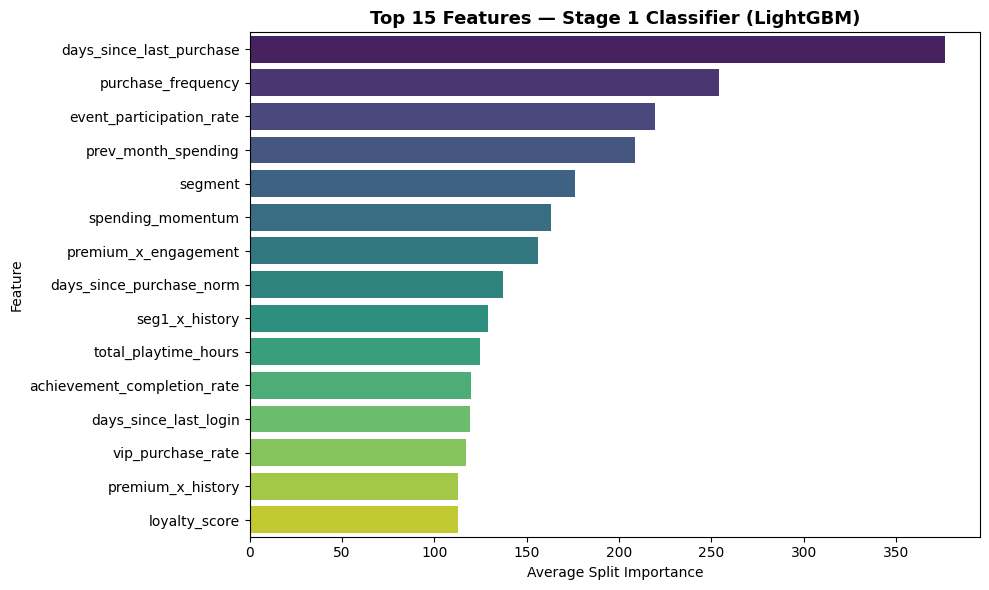

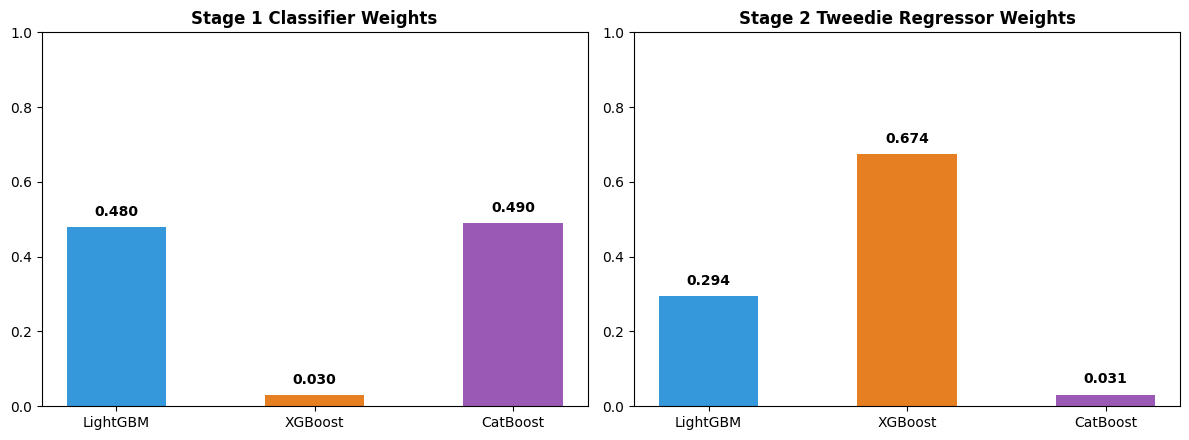

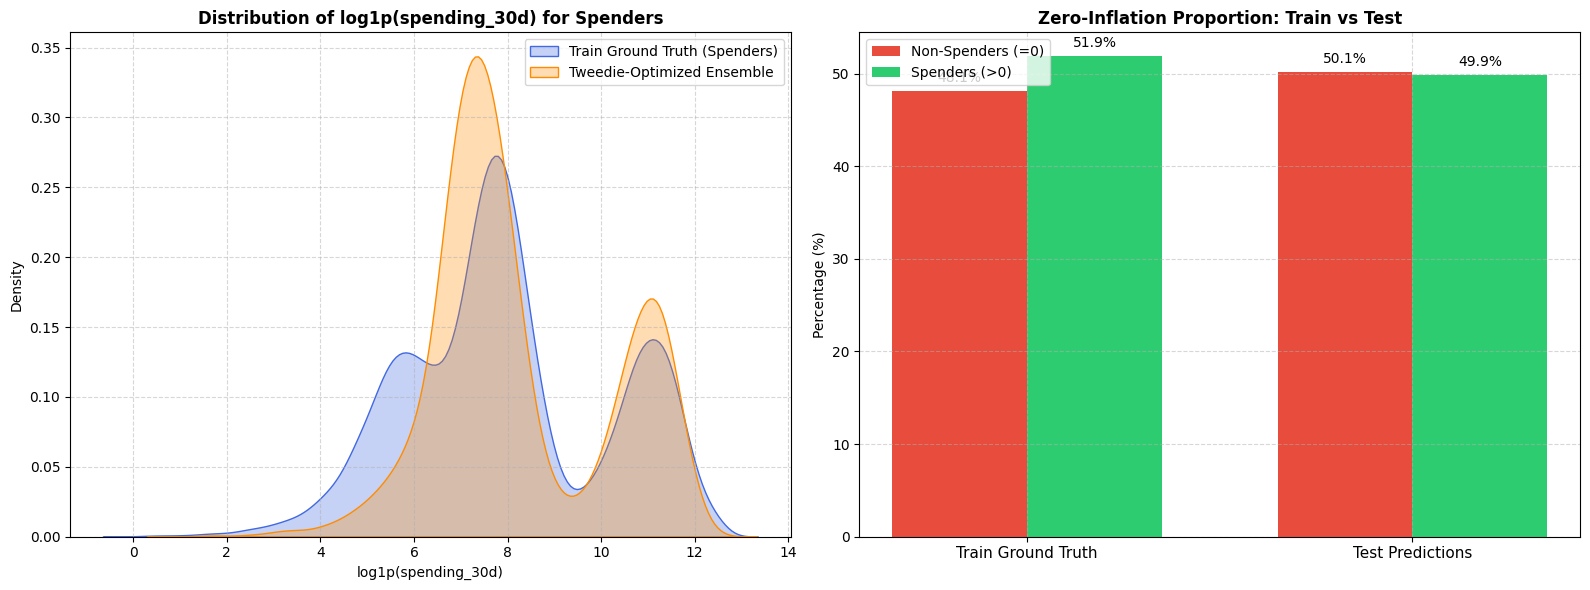

In [11]:
os.makedirs("outputs", exist_ok=True)

# 10.1 Stage 1 Feature Importance
avg_imp = np.mean([m.feature_importances_ for m in stage1_lgb_models], axis=0)
feat_imp_df = pd.DataFrame({"feature": selected_features, "importance": avg_imp}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(15), x="importance", y="feature", palette="viridis")
plt.title("Top 15 Features — Stage 1 Classifier (LightGBM)", fontsize=13, fontweight="bold")
plt.xlabel("Average Split Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("outputs/stage1_feature_importance.png", dpi=150)
plt.show()

# 10.2 Holy Trinity Convex Weights
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
models_lbl = ["LightGBM", "XGBoost", "CatBoost"]
colors_m = ["#3498db", "#e67e22", "#9b59b6"]

for ax, weights, title in [
    (axes[0], w_s1, "Stage 1 Classifier Weights"),
    (axes[1], w_s2, "Stage 2 Tweedie Regressor Weights")
]:
    ax.bar(models_lbl, weights, color=colors_m, width=0.5)
    ax.set_title(title, fontweight="bold")
    ax.set_ylim(0, 1.0)
    for i, v in enumerate(weights):
        ax.text(i, v + 0.03, f"{v:.3f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/holy_trinity_weights.png", dpi=150)
plt.show()

# 10.3 Ground Truth vs Tweedie-Optimized Ensemble Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
train_spenders = y_train[y_train > 0]
test_spenders = test_final_pred[test_final_pred > 0]

sns.kdeplot(np.log1p(train_spenders), ax=axes[0], label="Train Ground Truth (Spenders)", color="royalblue", fill=True, alpha=0.3)
sns.kdeplot(np.log1p(test_spenders), ax=axes[0], label="Tweedie-Optimized Ensemble", color="darkorange", fill=True, alpha=0.3)
axes[0].set_title("Distribution of log1p(spending_30d) for Spenders", fontsize=12, fontweight="bold")
axes[0].set_xlabel("log1p(spending_30d)")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

train_pct_spenders = float((y_train > 0).mean() * 100)
test_pct_spenders = float((test_final_pred > 0).mean() * 100)
x = np.arange(2)
width = 0.35
non_sp = [100.0 - train_pct_spenders, 100.0 - test_pct_spenders]
sp = [train_pct_spenders, test_pct_spenders]

axes[1].bar(x - width/2, non_sp, width, label="Non-Spenders (=0)", color="#e74c3c")
axes[1].bar(x + width/2, sp, width, label="Spenders (>0)", color="#2ecc71")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Train Ground Truth", "Test Predictions"], fontsize=11)
axes[1].set_ylabel("Percentage (%)")
axes[1].set_title("Zero-Inflation Proportion: Train vs Test", fontsize=12, fontweight="bold")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

for i in range(2):
    axes[1].text(i - width/2, non_sp[i] + 1.0, f"{non_sp[i]:.1f}%", ha="center", fontsize=10)
    axes[1].text(i + width/2, sp[i] + 1.0, f"{sp[i]:.1f}%", ha="center", fontsize=10)

plt.tight_layout()
plt.savefig("outputs/prediction_distribution_tweedie.png", dpi=150)
plt.show()

## 11. Robust Ensemble Blending & Submission Export

To maximize out-of-sample generalization and minimize prediction variance across heavy-tailed outliers, we combine the **Baseline Log-MAE Model** predictions (if available in `submissions/`) with our **Tweedie-Optimized Ensemble** predictions:
$$\hat{y}_{\text{final}} = 0.6 \cdot \hat{y}_{\text{Baseline}} + 0.4 \cdot \hat{y}_{\text{Tweedie}}$$
Finally, we verify row count (25,889), zero NaNs, and non-negativity before exporting `submissions/sub_task3.csv`.

In [12]:
EXPECTED_TEST_ROWS = 25889
assert len(test_final_pred) == EXPECTED_TEST_ROWS, f"Expected {EXPECTED_TEST_ROWS} rows, got {len(test_final_pred)}"
assert not np.isnan(test_final_pred).any(), "NaN detected in Tweedie-Optimized predictions."
assert (test_final_pred >= 0).all(), "Negative values detected in Tweedie-Optimized predictions."

sub_dirs = ["../submissions", "submissions", "../../submissions"]
target_sub_dir = next((d for d in sub_dirs if os.path.exists(d)), "../submissions")
os.makedirs(target_sub_dir, exist_ok=True)

# Save standalone Tweedie-Optimized Ensemble predictions
tweedie_sub_df = pd.DataFrame({"id": test_df[ID_COL], "task3": test_final_pred})
tweedie_path = os.path.join(target_sub_dir, "sub_task3_tweedie.csv")
tweedie_sub_df.to_csv(tweedie_path, index=False)
print(f"Saved Tweedie-Optimized Ensemble predictions to: {os.path.abspath(tweedie_path)}")

# Search for Baseline Log-MAE Model submission for Robust Ensemble Blending
candidate_baseline_files = [
    os.path.join(target_sub_dir, "sub_task3_baseline.csv"),
    os.path.join(target_sub_dir, "sub_task3_v1.csv"),
    os.path.join(target_sub_dir, "sub_task3.csv"),
    "submissions/sub_task3.csv",
    "../submissions/sub_task3.csv"
]
baseline_path = next((p for p in candidate_baseline_files if os.path.exists(p)), None)

if baseline_path is not None:
    print(f"Found Baseline Log-MAE submission: {os.path.abspath(baseline_path)}")
    baseline_df = pd.read_csv(baseline_path)
    assert len(baseline_df) == EXPECTED_TEST_ROWS, "Baseline submission row count mismatch."

    pred_col = "task3" if "task3" in baseline_df.columns else baseline_df.columns[1]
    baseline_preds = np.clip(baseline_df[pred_col].values.astype(np.float64), 0, None)

    # Robust Ensemble Blending: 0.6 * Baseline + 0.4 * Tweedie-Optimized
    final_blend_preds = np.clip(0.6 * baseline_preds + 0.4 * test_final_pred, 0, None)
    final_sub_df = pd.DataFrame({"id": test_df[ID_COL], "task3": final_blend_preds})

    blend_path = os.path.join(target_sub_dir, "sub_task3_blend.csv")
    official_path = os.path.join(target_sub_dir, "sub_task3.csv")
    final_sub_df.to_csv(blend_path, index=False)
    final_sub_df.to_csv(official_path, index=False)

    print(f"Saved Robust Ensemble Blend to : {os.path.abspath(blend_path)}")
    print(f"Updated Official Submission   : {os.path.abspath(official_path)}")
    print(f"Correlation (Baseline vs Tweedie): {np.corrcoef(baseline_preds, test_final_pred)[0, 1]:.4f}")
    print(f"Blended Spender Ratio         : {(final_sub_df['task3'] > 0).mean() * 100:.2f}%")
    display(final_sub_df.head())
else:
    official_path = os.path.join(target_sub_dir, "sub_task3.csv")
    tweedie_sub_df.to_csv(official_path, index=False)
    print("[INFO] Baseline submission not found; exported Tweedie-Optimized Ensemble as official sub_task3.csv.")
    display(tweedie_sub_df.head())

Saved Tweedie-Optimized Ensemble predictions to: d:\WORK\STUDY\Y3\CPE342 MACHINE LEARNING\Project-ML\cpe342-ML009\submissions\sub_task3_tweedie.csv
Found Baseline Log-MAE submission: d:\WORK\STUDY\Y3\CPE342 MACHINE LEARNING\Project-ML\cpe342-ML009\submissions\sub_task3.csv
Saved Robust Ensemble Blend to : d:\WORK\STUDY\Y3\CPE342 MACHINE LEARNING\Project-ML\cpe342-ML009\submissions\sub_task3_blend.csv
Updated Official Submission   : d:\WORK\STUDY\Y3\CPE342 MACHINE LEARNING\Project-ML\cpe342-ML009\submissions\sub_task3.csv
Correlation (Baseline vs Tweedie): 1.0000
Blended Spender Ratio         : 49.86%


,id,task3
0,P030374,0.000000
1,P113216,1807.308641
2,P015351,0.000000
3,P095374,0.000000
4,P059369,0.000000
